In [16]:
import sys
print(sys.executable)
from ytclickbait.config import load_config

/Users/ina/yt-clickbait/yt-clickbait/.venv/bin/python


In [17]:
import pandas as pd

from ytclickbait.config import load_config
from ytclickbait.rule_based_model_inputs import merge_rule_inputs

cfg = load_config()

# 실제 프로젝트 데이터 불러오기
videos = pd.read_parquet(cfg.file("videos"))
split = pd.read_parquet(cfg.file("split"))
rules = pd.read_parquet(cfg.file("rule_features"))

# 테스트를 통과한 함수로 입력을 검사하고 video_id 기준으로 병합하기
df = merge_rule_inputs(videos, split, rules)

# 아래 Ridge 학습 셀에서 사용할 14개 룰 피처 이름 보관하기
rule_cols = rules.columns.drop("video_id").tolist()

print(f"모델링 데이터: 영상 {len(df):,}개, 룰 피처 {len(rule_cols)}개")
display(df[["title", "log_views", "split_time", "n_exclaim", "caps_ratio"]].head())

모델링 데이터: 영상 78,180개, 룰 피처 14개


,title,log_views,split_time,n_exclaim,caps_ratio
0,Jadon Sancho • Magical Skills & Goals,12.979280,train,0,0.172414
1,Migos - Avalanche (Official Video),15.735846,excluded,0,0.148148
2,MY TESLA PAYS FOR ITSELF,13.245354,excluded,0,1.000000
3,Supporting Actress in a Comedy: 73rd Emmys,13.433679,train,0,0.121212
4,San Francisco 49ers vs. Arizona Cardinals Game...,14.478602,test,0,0.185185


In [18]:
import pandas as pd
from ytclickbait.config import load_config

cfg = load_config()

videos = pd.read_parquet(cfg.file("videos"))
split = pd.read_parquet(cfg.file("split"))
rules = pd.read_parquet(cfg.file("rule_features"))

print("number of videos:", len(videos))
print("number of split rows:", len(split))
print("number of rule features:", len(rules.columns.drop("video_id")))

display(rules.head(3))

number of videos: 78180
number of split rows: 78180
number of rule features: 14


,video_id,n_chars,n_words,caps_ratio,n_caps_words,n_exclaim,n_question,has_number,starts_with_number,n_emoji,has_brackets,has_pipe_or_colon,has_hashtag,has_second_person,n_clickbait_words
0,--0bCF-iK2E,37,7,0.172414,0,0,0,0,0,0,0,0,0,0,0
1,--14w5SOEUs,34,5,0.148148,0,0,0,0,0,0,1,0,0,0,0
2,--2O86Z0hsM,24,5,1.000000,5,0,0,0,0,0,0,0,0,0,0


In [5]:
# split train and test

train = df.loc[df["split_time"] == "train"].copy()
test = df.loc[df["split_time"] == "test"].copy()

print(f"train: {len(train):,}")
print(f"test: {len(test):,}")
print(f"excluded: {(df['split_time'] == 'excluded').sum():,}")

train: 42,204
test: 11,487
excluded: 24,489


In [19]:
# baseline model

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = ["log_age_days", "channel_baseline_split_time"]
category_cols = ["category_name", "publish_week"]
control_cols = numeric_cols + category_cols

preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
])

baseline = make_pipeline(preprocess, Ridge(alpha=1.0, solver="lsqr"))

baseline.fit(train[control_cols], train["log_views"])

baseline_pred = baseline.predict(test[control_cols])

baseline_rmse = mean_squared_error(test["log_views"], baseline_pred) ** 0.5
baseline_r2 = r2_score(test["log_views"], baseline_pred)

print(f"Baseline Model RMSE: {baseline_rmse:.4f}")
print(f"Baseline Model R²:   {baseline_r2:.4f}")

Baseline Model RMSE: 0.7385
Baseline Model R²:   0.5953


In [20]:
# numeric_cols + rule_cols

numeric_with_rules = numeric_cols + rule_cols
input_cols = numeric_with_rules + category_cols

rules_preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_with_rules),
    ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
])

rules_model = make_pipeline(rules_preprocess, Ridge(alpha=1.0, solver="lsqr"))
rules_model.fit(train[input_cols], train["log_views"])

rules_pred = rules_model.predict(test[input_cols])
rules_rmse = mean_squared_error(test["log_views"], rules_pred) ** 0.5
rules_r2 = r2_score(test["log_views"], rules_pred)

results = pd.DataFrame({
    "Model": ["numeric_cols", "numeric_cols + rule_cols_14"],
    "RMSE": [baseline_rmse, rules_rmse],
    "R²": [baseline_r2, rules_r2],
})
display(results.round(4))

,Model,RMSE,R²
0,numeric_cols,0.7385,0.5953
1,numeric_cols + rule_cols_14,0.7350,0.5992


In [21]:
# 1. train & test
group_train = df.loc[df["split_group"] == "train"]
group_test = df.loc[df["split_group"] == "test"]

# Check if test dataset not in train dataset
assert set(group_train["channel_id"]).isdisjoint(group_test["channel_id"])

# 2. Compare 
group_controls = ["log_age_days", "channel_baseline_split_group"]
group_scores = {}

for name, extra_cols in [("control_variables", []), ("control_variables + rule_based_features", rule_cols)]:
    num_cols = group_controls + extra_cols
    x_cols = num_cols + category_cols

    preprocess_group = ColumnTransformer([
        ("numeric", StandardScaler(), num_cols),
        ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ])
    model = make_pipeline(preprocess_group, Ridge(alpha=1.0, solver="lsqr"))
    model.fit(group_train[x_cols], group_train["log_views"])

    pred = model.predict(group_test[x_cols])
    group_scores[name] = {
        "RMSE": mean_squared_error(group_test["log_views"], pred) ** 0.5,
        "R²": r2_score(group_test["log_views"], pred),
    }

display(pd.DataFrame(group_scores).T.round(4))

,RMSE,R²
control_variables,1.2048,0.1180
control_variables + rule_based_features,1.2029,0.1207


In [9]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train = df.loc[df["split_time"] == "train"]
test = df.loc[df["split_time"] == "test"]

numeric_controls = ["log_age_days", "channel_baseline_split_time"]
category_cols = ["category_name", "publish_week"]

rows = []

for name, extra_cols in [
    ("Control Variables", []),
    ("Control Variables + Rule Features", rule_cols),
]:
    numeric_cols = numeric_controls + extra_cols
    input_cols = numeric_cols + category_cols

    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ])
    model = make_pipeline(preprocess, Ridge(alpha=1.0, solver="lsqr"))
    model.fit(train[input_cols], train["log_views"])

    pred = model.predict(test[input_cols])
    rows.append({
        "Model": name,
        "RMSE": mean_squared_error(test["log_views"], pred) ** 0.5,
        "R²": r2_score(test["log_views"], pred),
    })

results = pd.DataFrame(rows)
display(pd.DataFrame(results).round(4))

,Model,RMSE,R²
0,Control Variables,0.7385,0.5953
1,Control Variables + Rule Features,0.7350,0.5992


In [10]:
# Scaling

from time import perf_counter

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

# 기존 split_group 실험과 동일한 통제변수를 사용해요.
# category_cols는 모델링 노트북에서 정의한 범주형 통제변수 목록이에요.
control_cols = ["log_age_days", "channel_baseline_split_group"]

# 비교할 두 모델의 차이는 제목 룰 피처 14개를 넣는지 여부예요.
assert len(rule_cols) == 14
models_to_compare = [
    ("통제변수만", control_cols),
    ("통제변수 + 룰 피처", control_cols + list(rule_cols)),
]

# 학습 시간 실험이므로 split_group의 train 영상만 사용해요.
# 필요한 열만 가져와 제목 원문 등 사용하지 않는 열은 메모리에서 제외해요.
needed_cols = control_cols + list(category_cols) + list(rule_cols) + ["log_views"]
train_pool = df.loc[df["split_group"].eq("train"), needed_cols]

# 영상을 한 번만 섞어요. 이후 앞에서부터 자르면
# 5천 개 영상이 2만 개에 포함되고, 2만 개가 다시 5만 개에 포함돼요.
sample_sizes = [5_000, 20_000, 50_000]
assert len(train_pool) >= max(sample_sizes), f"학습 영상은 {len(train_pool):,}개예요."
train_pool = train_pool.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"사용 가능한 학습 영상 {len(train_pool):,}개")

사용 가능한 학습 영상 63,437개


In [11]:
def measure_training_time(sample, numeric_cols):
    """같은 영상 표본으로 전처리와 Ridge 학습에 걸린 시간을 초 단위로 반환해요."""

    # 모델에 사용할 입력 X와 예측 대상 y를 준비해요.
    # 데이터 선택이 끝난 뒤 타이머를 시작해요.
    X = sample[numeric_cols + list(category_cols)]
    y = sample["log_views"]

    # 기존 모델링 실험처럼 숫자형 열은 표준화하고 범주형 열은 원핫 인코딩해요.
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ])
    model = Ridge(alpha=1.0, solver="lsqr")

    # 첫 번째 구간은 원래 표를 모델 입력 행렬로 변환하는 시간이에요.
    start = perf_counter()
    X_ready = preprocess.fit_transform(X)
    after_preprocess = perf_counter()

    # 두 번째 구간은 변환된 행렬로 Ridge를 학습하는 시간이에요.
    model.fit(X_ready, y)
    after_fit = perf_counter()

    return {
        "전처리(초)": after_preprocess - start,
        "Ridge 학습(초)": after_fit - after_preprocess,
        "전체(초)": after_fit - start,
    }


records = []

# 같은 컴퓨터에서도 연산 스레드 수에 따라 시간이 달라질 수 있어요.
# 두 모델 모두 같은 조건에서 비교하도록 연산 라이브러리의 스레드를 1개로 맞춰요.
with threadpool_limits(limits=1):
    # 각 모델을 소량의 데이터로 한 번 실행해 첫 호출의 초기화 비용을 줄여요.
    # 이 준비 실행은 측정 결과에 기록하지 않아요.
    for _, numeric_cols in models_to_compare:
        measure_training_time(train_pool.iloc[:500], numeric_cols)

    for n in sample_sizes:
        # 이 크기에서 두 모델은 정확히 같은 영상과 같은 log_views로 학습해요.
        sample = train_pool.iloc[:n]

        # 각 조건을 6회 반복하고, 어느 한 모델이 계속 먼저 실행되지 않게
        # 홀수 번째와 짝수 번째 반복의 실행 순서를 바꿔요.
        for repeat in range(6):
            order = models_to_compare if repeat % 2 == 0 else models_to_compare[::-1]

            for model_name, numeric_cols in order:
                times = measure_training_time(sample, numeric_cols)
                records.append({
                    "학습 영상 수": n,
                    "반복": repeat + 1,
                    "모델": model_name,
                    **times,
                })

# 각 실행의 시간을 보관해 나중에 반복 간 차이도 확인할 수 있어요.
timings = pd.DataFrame(records)

Matplotlib is building the font cache; this may take a moment.


전처리(초)  Ridge 학습(초)   전체(초)
학습 영상 수 모델                                      
5000    통제변수 + 룰 피처  0.0355       0.0146  0.0498
        통제변수만        0.0357       0.0063  0.0419
20000   통제변수 + 룰 피처  0.1139       0.0295  0.1436
        통제변수만        0.0976       0.0074  0.1050
50000   통제변수 + 룰 피처  0.2839       0.0695  0.3554
        통제변수만        0.2385       0.0177  0.2560

,추가 전처리(초),추가 Ridge 학습(초),추가 전체(초)
학습 영상 수,,,
5000,0.0015,0.0084,0.0098
20000,0.0147,0.0220,0.0367
50000,0.0350,0.0517,0.1054


/var/folders/hl/d8v16q9d4wbc1hhcb_vxwmm80000gn/T/ipykernel_17975/887121678.py:32: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/hl/d8v16q9d4wbc1hhcb_vxwmm80000gn/T/ipykernel_17975/887121678.py:32: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/ina/yt-clickbait/yt-clickbait/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/ina/yt-clickbait/yt-clickbait/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


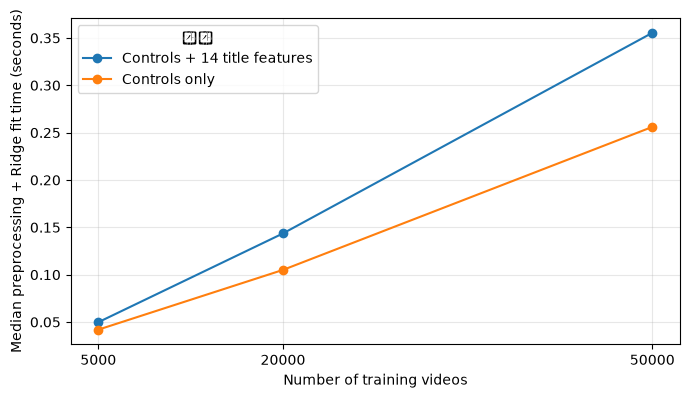

In [12]:
import matplotlib.pyplot as plt

time_cols = ["전처리(초)", "Ridge 학습(초)", "전체(초)"]

# 표 1. 영상 수와 모델별로 6회 측정한 시간의 중앙값을 보여줘요.
summary = timings.groupby(["학습 영상 수", "모델"])[time_cols].median()
display(summary.round(4))

# 표 2. 같은 영상 수, 같은 반복에서 두 모델의 시간을 짝지어 빼요.
# 예를 들어 1회차의 '룰 피처 추가 모델'에서 1회차의 '통제변수 모델' 시간을 빼요.
paired = timings.pivot(index=["학습 영상 수", "반복"], columns="모델", values=time_cols)
extra_time = (
    paired.xs("통제변수 + 룰 피처", axis=1, level="모델")
    - paired.xs("통제변수만", axis=1, level="모델")
)

# 반복마다 계산한 추가 시간의 중앙값을 구해요.
extra_summary = extra_time.groupby(level="학습 영상 수").median()
extra_summary.columns = ["추가 전처리(초)", "추가 Ridge 학습(초)", "추가 전체(초)"]
display(extra_summary.round(4))

# 그래프. 영상 수가 늘 때 두 모델의 전체 시간이 어떻게 달라지는지 비교해요.
plot_data = summary["전체(초)"].unstack("모델").rename(columns={
    "통제변수만": "Controls only",
    "통제변수 + 룰 피처": "Controls + 14 title features",
})
ax = plot_data.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Number of training videos")
ax.set_ylabel("Median preprocessing + Ridge fit time (seconds)")
ax.set_xticks(sample_sizes)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()